# Load type classification

Predict `Load_Type` (Light / Medium / Maximum) for every 15-minute reading of a steel plant's power system in 2018.

Plan: clean the obvious data problems, look at how the label relates to time and consumption, build a small set of
calendar and electrical features, compare a few models with time-ordered cross-validation on January-November, and
evaluate the chosen model once on December, which is held out the whole time.

In [1]:
import time
from pathlib import Path
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
from IPython.display import Markdown, display
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, cohen_kappa_score, confusion_matrix,
                             f1_score, log_loss, matthews_corrcoef, precision_recall_fscore_support,
                             roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

started = time.perf_counter()
SEED = 42
THREADS = 4
LABELS = ['Light_Load', 'Medium_Load', 'Maximum_Load']
COLORS = ['#4c78a8', '#f2a541', '#e45756']
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', None)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})


## Inspect the injected corruption

I read the measurement columns as text before converting them to numbers. The original readings have at most
two decimal places; longer decimals identify injected values even when they fall inside a plausible range.
The table counts these separately from missing values and compares their maxima with the original readings.


In [2]:
RAW = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh',
       'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']
MEASUREMENTS = RAW + ['NSM']
text = pd.read_csv('data/load_data.csv', dtype={col: str for col in MEASUREMENTS})
numeric = text[MEASUREMENTS].apply(pd.to_numeric)
long_decimal = text[MEASUREMENTS].apply(
    lambda s: s.str.extract(r'\.(\d+)(?:[eE].*)?$', expand=False).str.len().gt(2))
raw = text.copy()
raw[MEASUREMENTS] = numeric
raw['Date_Time'] = pd.to_datetime(raw['Date_Time'], format='%d-%m-%Y %H:%M')
decimal_audit = pd.DataFrame({'missing': numeric.isna().sum(), 'long decimals': long_decimal.sum(),
                              'long % of observed': 100 * long_decimal.sum() / numeric.notna().sum(),
                              'max, original precision': numeric.mask(long_decimal).max(),
                              'max, long decimals': numeric.where(long_decimal).max()})
display(decimal_audit.round(4))
print(f'Rows without any long-decimal value: {(~long_decimal.any(axis=1)).sum():,} (missing values allowed)')
range_invalid = numeric.lt(0)
for col in RAW[4:]:
    range_invalid[col] |= numeric[col].gt(100)
range_invalid['NSM'] |= numeric['NSM'].gt(86400)
print('All out-of-range values have long decimals:', not (range_invalid & ~long_decimal).any().any())


,missing,long decimals,long % of observed,"max, original precision","max, long decimals"
Usage_kWh,1559,3358,10.0293,153.14,435.0191
Lagging_Current_Reactive.Power_kVarh,876,2710,7.9321,96.91,262.6307
Leading_Current_Reactive_Power_kVarh,1156,1137,3.3555,27.76,78.8090
CO2(tCO2),455,1369,3.9582,0.07,0.1882
Lagging_Current_Power_Factor,350,3461,9.9767,100.00,299.9968
Leading_Current_Power_Factor,1471,3346,9.9672,100.00,299.9695
NSM,455,3414,9.8710,85500.00,248821.8105


Rows without any long-decimal value: 20,002 (missing values allowed)
All out-of-range values have long decimals: True


## Correct the interval timestamps

The midnight row follows 23:45 of its written date, so I move every 00:00 timestamp forward one day. The only
remaining ordering wrinkle is the extra 31 December 20:00 row appended to the file; I drop that second copy.
I use interval-end timestamps and recompute NSM as seconds since midnight, with 00:00 represented by 0.


In [3]:
midnight = raw['Date_Time'].dt.hour.eq(0) & raw['Date_Time'].dt.minute.eq(0)
corrected_time = raw['Date_Time'] + pd.to_timedelta(midnight.astype(int), unit='D')
ordering = pd.DataFrame({'written': raw['Date_Time'], 'corrected': corrected_time})
display(ordering.loc[corrected_time.diff().ne(pd.Timedelta('15min'))])
duplicates = corrected_time.duplicated(keep='first')
display(raw.loc[corrected_time.duplicated(keep=False)])
assert duplicates.sum() == 1
keep = ~duplicates
duplicate_positions = raw.index[corrected_time.duplicated(keep=False)]
assert keep.loc[duplicate_positions[0]] and not keep.loc[duplicate_positions[1]]
assert numeric.loc[duplicate_positions[0], 'Usage_kWh'] == 4.14
assert numeric.loc[duplicate_positions[0], 'Lagging_Current_Power_Factor'] == 100
assert pd.isna(numeric.loc[duplicate_positions[1], 'Usage_kWh'])
print('I keep the earlier-in-file duplicate (usage 4.14, lagging PF 100), not the appended noisy copy.')
month_changes = raw['Date_Time'].dt.to_period('M').ne(corrected_time.dt.to_period('M'))
assert month_changes.sum() == 12
print(f'Midnight readings crossing calendar-month boundaries: {month_changes.sum()}')
display(ordering.loc[month_changes])
timeline = pd.DatetimeIndex(corrected_time[keep], name='Date_Time')
expected = pd.date_range('2018-01-01 00:15', '2019-01-01 00:00', freq='15min', name='Date_Time')
assert timeline.equals(expected)
assert timeline.is_unique and timeline.is_monotonic_increasing
observed = numeric.loc[keep].set_axis(timeline)
corrupted = (long_decimal | range_invalid).loc[keep].set_axis(timeline)
trusted = observed.mask(corrupted)
reporting_date = (timeline - pd.Timedelta('15min')).normalize()
# Split on corrected interval-end timestamps; the boundary interval still starts in November.
train_mask = timeline <= pd.Timestamp('2018-12-01 00:00')
test_mask = ~train_mask
print(f'{len(timeline):,} strictly increasing 15-minute intervals; {midnight.sum()} midnight dates corrected')

boundary_row = raw['Date_Time'].eq(pd.Timestamp('2018-11-30 00:00'))
assert corrected_time[boundary_row].iloc[0] == pd.Timestamp('2018-12-01 00:00')
assert pd.Timestamp('2018-12-01 00:00') in timeline[train_mask]
assert timeline[test_mask].equals(pd.date_range('2018-12-01 00:15', '2019-01-01 00:00', freq='15min', name='Date_Time'))
print('Written 30 November 00:00 -> corrected 1 December 00:00 -> training (last November interval).')


,written,corrected
0,2018-01-01 00:15:00,2018-01-01 00:15:00
35040,2018-12-31 20:00:00,2018-12-31 20:00:00


,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
35023,2018-12-31 20:00:00,4.14,0.0,20.09,0.0,100.00000,20.18,72000.0,Light_Load
35040,2018-12-31 20:00:00,NaN,0.0,20.10,0.0,217.27347,20.19,72000.0,Light_Load


I keep the earlier-in-file duplicate (usage 4.14, lagging PF 100), not the appended noisy copy.
Midnight readings crossing calendar-month boundaries: 12


,written,corrected
2975,2018-01-31,2018-02-01
5663,2018-02-28,2018-03-01
8639,2018-03-31,2018-04-01
11519,2018-04-30,2018-05-01
14495,2018-05-31,2018-06-01
17375,2018-06-30,2018-07-01
20351,2018-07-31,2018-08-01
23327,2018-08-31,2018-09-01
26207,2018-09-30,2018-10-01
29183,2018-10-31,2018-11-01


35,040 strictly increasing 15-minute intervals; 365 midnight dates corrected
Written 30 November 00:00 -> corrected 1 December 00:00 -> training (last November interval).


I split on the corrected interval-end timestamps: **December is 1 December 2018 00:15 through 1 January 2019
00:00 inclusive, 2,976 readings**. The written 30 November 00:00 reading becomes 1 December 00:00 and stays
in training, because its interval starts on 30 November at 23:45; training has 32,064 readings.
I use the interval's starting date when grouping whole days for the bootstrap and weekday/weekend error counts.


## Check the same-row physical relationships

I compare each power factor with `100 * kWh / hypot(kWh, reactive power)`. On rows without any long decimals,
both identities hold for every available triplet, within the original 0.01-point rounding. I also show how often
the lagging identity holds when usage has long decimals, using a generous 0.6-point tolerance.


In [4]:
U, QL, QD, C, PL, PD = RAW
no_long = (~long_decimal.any(axis=1)).loc[keep].set_axis(timeline)
identity_rows = []
for q, p in [(QL, PL), (QD, PD)]:
    expected_pf = 100 * observed[U] / np.hypot(observed[U], observed[q])
    error = (observed[p] - expected_pf).abs()
    for name, mask in [('no long decimals', no_long), ('long-decimal usage', corrupted[U]),
                       ('long usage, trusted reactive/PF', corrupted[U] & ~corrupted[q] & ~corrupted[p])]:
        values = error[mask].dropna()
        identity_rows.append({'identity': p, 'rows': name, 'available triplets': len(values),
                               'within 0.6 (%)': 100 * values.le(.6).mean(), 'max error': values.max()})
display(pd.DataFrame(identity_rows).set_index(['identity', 'rows']).round(5))


available triplets  \
identity                     rows                                                  
Lagging_Current_Power_Factor no long decimals                              18311   
                             long-decimal usage                             3241   
                             long usage, trusted reactive/PF                2685   
Leading_Current_Power_Factor no long decimals                              17514   
                             long-decimal usage                             3111   
                             long usage, trusted reactive/PF                2688   

                                                              within 0.6 (%)  \
identity                     rows                                              
Lagging_Current_Power_Factor no long decimals                      100.00000   
                             long-decimal usage                     23.51126   
                             long usage, trusted reactive/PF        27.44879   
Leading_Current_Power_Factor no long decimals                      100.00000   
                             long-decimal usage                     68.01671   
                             long usage, trusted reactive/PF        77.26935   

                                                              max error  
identity                     rows                                        
Lagging_Current_Power_Factor no long decimals                   0.00500  
                             long-decimal usage               197.08075  
                             long usage, trusted reactive/PF   38.77866  
Leading_Current_Power_Factor no long decimals                   0.00500  
                             long-decimal usage               199.89132  
                             long usage, trusted reactive/PF   38.96122

CO2 is rounded to 0.01 tonnes, so it cannot uniquely recover usage. I estimate its forward conversion factor
from trusted pairs in the **first CV training block only**, by checking agreement after rounding to two decimals.
This freezes the cleaning rule before any validation block or December. I then invalidate trusted CO2 values that disagree with the rounded identity by more than 0.01 tonnes.


In [5]:
first_training = next(TimeSeriesSplit(n_splits=5).split(trusted.loc[train_mask]))[0]
factor_data = trusted.iloc[first_training][[U, C]].dropna()
factors = np.linspace(.0004, .0006, 2001)
matches = np.array([np.isclose((factor_data[U] * f).round(2), factor_data[C]).mean() for f in factors])
CO2_FACTOR = float(factors[matches.argmax()])
co2_pairs = trusted.loc[train_mask, [U, C]].dropna()
co2_audit = pd.DataFrame([
    {'factor': f, 'Jan-Nov pairs': len(co2_pairs),
     'exact after rounding (%)': 100 * np.isclose((co2_pairs[U] * f).round(2), co2_pairs[C]).mean()}
    for f in [.00045, CO2_FACTOR, .00046, .0005]])
display(co2_audit.round(7))
print(f'Frozen CO2 factor: {CO2_FACTOR:.7f}; first-block agreement {matches.max():.2%}')


,factor,Jan-Nov pairs,exact after rounding (%)
0,0.000450,26161,97.756202
1,0.000458,26161,99.835633
2,0.000460,26161,99.506900
3,0.000500,26161,89.438477


Frozen CO2 factor: 0.0004585; first-block agreement 99.01%


I reconstruct 41 trusted CO2 values that disagree with the rounded usage identity by more than 0.01, all on 2 January; two other zero-CO2 readings are within 0.01 of the identity, so I leave them.


In [6]:
co2_expected = (trusted[U] * CO2_FACTOR).round(2)
# Avoid treating binary floating-point representations of exactly 0.01 as greater than 0.01.
co2_identity_invalid = (trusted[C] - co2_expected).abs().gt(.01 + 1e-12)
zero_energy_rows = trusted[[U, QL, QD]].eq(0).all(axis=1)
print(f'CO2 identity repairs: {co2_identity_invalid.sum()} cells; '
      f'{trusted.index[co2_identity_invalid].min()} to {trusted.index[co2_identity_invalid].max()}')
print(f'All-zero energy rows: {zero_energy_rows.sum()}; '
      f'{trusted.index[zero_energy_rows].tolist()}; {2 * zero_energy_rows.sum()} PF cells set to NaN')
corrupted.loc[co2_identity_invalid, C] = True
corrupted.loc[zero_energy_rows, [PL, PD]] = True
trusted = observed.mask(corrupted)


CO2 identity repairs: 41 cells; 2018-01-02 08:30:00 to 2018-01-02 20:15:00
All-zero energy rows: 1; [Timestamp('2018-11-08 00:00:00')]; 2 PF cells set to NaN


I set both power factors to NaN on the one all-zero energy/reactive-power row, at corrected time
8 November 2018 00:00, because the ratio is undefined there.


## Reconstruct missing and corrupted measurements

I recover usage from a trusted lagging pair first, then a leading pair if needed:
`kWh = PF * kVarh / sqrt(10000 - PF²)`. I recover reactive power from usage and PF, PF from usage and reactive
power, and CO2 from usage. I only fill missing entries, and every source is from that same row.

PF must be below 100 and reactive power positive to recover usage. Near 100, rounding makes the inverse unstable:
I propagate the original ±0.005 rounding through the inverse and leave it missing if the resulting bound exceeds
0.6 in the recovered unit. There is no time interpolation or recovery of usage from rounded CO2.


In [7]:
def usage_from_pair(q, p):
    def inverse(q_value, p_value):
        return p_value * q_value / np.sqrt(10000 - p_value ** 2)
    eligible = q.gt(0) & p.ge(0) & p.lt(100)
    q, p = q.where(eligible), p.where(eligible)
    estimate = inverse(q, p)
    lower = inverse((q - .005).clip(lower=0), (p - .005).clip(lower=0))
    upper = inverse(q + .005, (p + .005).where(p + .005 < 100))
    bound = pd.concat([estimate - lower, upper - estimate], axis=1).max(axis=1, skipna=False)
    return estimate.where(bound.le(.6)).round(2)


def reactive_from_pair(u, p):
    def inverse(u_value, p_value):
        return u_value * np.sqrt(10000 - p_value ** 2) / p_value
    eligible = u.ge(0) & p.gt(0) & p.le(100)
    u, p = u.where(eligible), p.where(eligible)
    estimate = inverse(u, p)
    lower = inverse((u - .005).clip(lower=0), (p + .005).clip(upper=100))
    upper = inverse(u + .005, (p - .005).where(p - .005 > 0))
    bound = pd.concat([estimate - lower, upper - estimate], axis=1).max(axis=1, skipna=False)
    return estimate.where(bound.le(.6)).round(2)


def reconstruct(frame):
    result = frame.copy()
    result[U] = result[U].fillna(usage_from_pair(result[QL], result[PL]))
    result[U] = result[U].fillna(usage_from_pair(result[QD], result[PD]))
    for q, p in [(QL, PL), (QD, PD)]:
        result[q] = result[q].fillna(reactive_from_pair(result[U], result[p]))
        denominator = np.hypot(result[U], result[q])
        estimate_pf = (100 * result[U] / denominator.where(denominator.gt(0))).round(2)
        result[p] = result[p].fillna(estimate_pf)
    # With no active or reactive energy, both power factors are undefined.
    zero_energy = result[[U, QL, QD]].eq(0).all(axis=1)
    result.loc[zero_energy, [PL, PD]] = np.nan
    result[C] = result[C].fillna((result[U] * CO2_FACTOR).round(2))
    result['NSM'] = result.index.hour * 3600 + result.index.minute * 60
    return result


cleaned = reconstruct(trusted)
repair_audit = pd.DataFrame({'originally missing': observed.isna().sum(),
                             'flagged corrupted': corrupted.sum(),
                             'repaired from same row': (trusted.isna() & cleaned.notna()).sum(),
                             'remaining NaN': cleaned.isna().sum()})
# NSM is recomputed for every row, including those whose original value happened to agree.
repair_audit.loc['NSM', 'repaired from same row'] = len(cleaned)
display(repair_audit)
print('NSM count includes all timestamp-derived replacements.')
df = cleaned.copy()
df['Load_Type'] = raw.loc[keep, 'Load_Type'].to_numpy()
train, test = df.loc[train_mask], df.loc[test_mask]
print(f'train: {len(train):,} rows ({train.index.min()} to {train.index.max()})')
print(f'test: {len(test):,} rows ({test.index.min()} to {test.index.max()})')


,originally missing,flagged corrupted,repaired from same row,remaining NaN
Usage_kWh,1558,3358,3797,1119
Lagging_Current_Reactive.Power_kVarh,876,2710,2833,753
Leading_Current_Reactive_Power_kVarh,1156,1137,1595,698
CO2(tCO2),455,1410,1800,65
Lagging_Current_Power_Factor,350,3461,3059,752
Leading_Current_Power_Factor,1471,3347,4273,545
NSM,455,3414,35040,0


NSM count includes all timestamp-derived replacements.
train: 32,064 rows (2018-01-01 00:15:00 to 2018-12-01 00:00:00)
test: 2,976 rows (2018-12-01 00:15:00 to 2019-01-01 00:00:00)


I check reconstruction by hiding one value at a time on complete, originally trusted January-November rows and running
the same function. The table reports coverage, mean absolute error, 95th-percentile absolute error and maximum
error in each column's own units. This checks single missing values; multiple missing inputs can reduce coverage and compound rounding error.


In [8]:
reconstruction_rows = []
clean_development = trusted.loc[train_mask & trusted.notna().all(axis=1)]
for col in MEASUREMENTS:
    masked = clean_development.copy()
    known = masked[col].notna()
    truth = masked[col].copy()
    masked[col] = np.nan
    recovered = reconstruct(masked)[col]
    error = (recovered[known] - truth[known]).abs().dropna()
    reconstruction_rows.append({'column': col, 'masked': int(known.sum()), 'recovered': len(error),
                                 'MAE': error.mean(), '95% absolute error': error.quantile(.95),
                                 'max absolute error': error.max()})
reconstruction_check = pd.DataFrame(reconstruction_rows).set_index('column')
display(reconstruction_check.round(5))
# Row-local cleaning cannot change earlier rows when later rows are added.
pd.testing.assert_frame_equal(cleaned.iloc[:6000], reconstruct(trusted.iloc[:6000]))


,masked,recovered,MAE,95% absolute error,max absolute error
column,,,,,
Usage_kWh,15006,14886,0.00746,0.03,0.45
Lagging_Current_Reactive.Power_kVarh,15006,15006,0.00341,0.01,0.36
Leading_Current_Reactive_Power_kVarh,15006,12405,0.00459,0.01,0.54
CO2(tCO2),15006,15006,0.00000,0.00,0.01
Lagging_Current_Power_Factor,15006,15006,0.00000,0.00,0.00
Leading_Current_Power_Factor,15006,15006,0.00000,0.00,0.00
NSM,15006,15006,0.00000,0.00,0.00


## Check the labels

I check spelling, the early-morning labels, and isolated one-reading flips on January-November only. I keep all
labels unchanged: these checks are diagnostics, and I don't infer new labels from measurements or schedule rules.


In [9]:
assert set(raw['Load_Type']) == set(LABELS)
labels = train['Load_Type']
early = train.index.hour * 60 + train.index.minute <= 8 * 60
isolated = labels.ne(labels.shift(1)) & labels.ne(labels.shift(-1)) & labels.shift(1).eq(labels.shift(-1))
print('Label spellings:', sorted(raw['Load_Type'].unique()))
print('Non-Light labels from 00:00 through 08:00:', labels[early].ne('Light_Load').sum())
print('Isolated one-reading flips:', isolated.sum())


Label spellings: ['Light_Load', 'Maximum_Load', 'Medium_Load']
Non-Light labels from 00:00 through 08:00: 0
Isolated one-reading flips: 0


## EDA (January-November only)

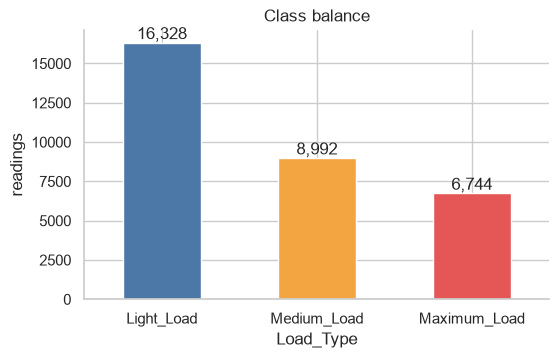

In [10]:
counts = train['Load_Type'].value_counts().reindex(LABELS)
ax = counts.plot.bar(color=COLORS, rot=0, figsize=(6, 3.5), title='Class balance')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
ax.set_ylabel('readings')
plt.show()

Light load is over half the data, so I use macro F1 as the main metric; accuracy alone would reward predicting
Light_Load too often.

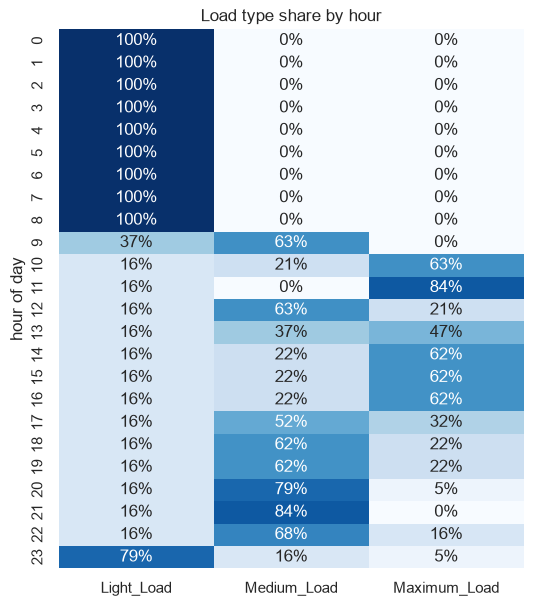

In [11]:
by_hour = pd.crosstab(train.index.hour, train['Load_Type'], normalize='index')[LABELS]
fig, ax = plt.subplots(figsize=(6, 7))
sns.heatmap(by_hour, annot=True, fmt='.0%', cmap='Blues', cbar=False, ax=ax)
ax.set(title='Load type share by hour', xlabel='', ylabel='hour of day')
plt.show()

The clock explains a lot: midnight to 9am is always Light_Load, and the daytime mix shifts hour by hour. About 17% of
daytime readings are still Light_Load, which points to days when the plant isn't running at full schedule.

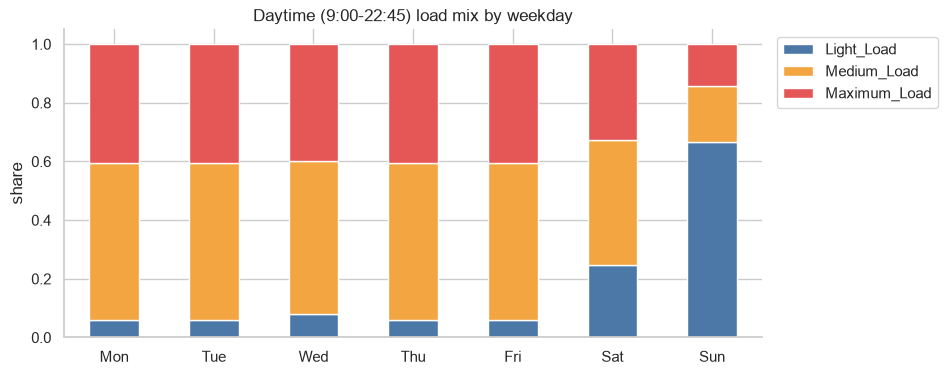

In [12]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
daytime = train[train.index.hour.isin(range(9, 23))]
by_day = pd.crosstab(daytime.index.day_of_week, daytime['Load_Type'], normalize='index')[LABELS]
ax = by_day.set_axis(days).plot.bar(stacked=True, color=COLORS, rot=0, title='Daytime (9:00-22:45) load mix by weekday')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
ax.set_ylabel('share')
plt.show()

About two thirds of Sunday daytime readings are Light_Load, a quarter on Saturdays, and only ~6% on weekdays (holidays and the odd shutdown).

The schedule also changes with the season. Looking at the most common label for each weekday hour, month by month,
Maximum_Load moves from late morning/afternoon in March-October to the evening in November-February:

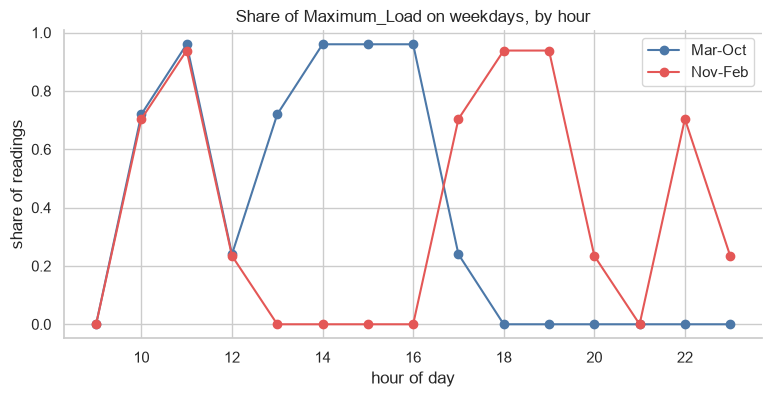

In [13]:
weekdays = train[(train.index.day_of_week < 5) & (train.index.hour >= 9)]
season = np.where(weekdays.index.month.isin([11, 12, 1, 2]), 'Nov-Feb', 'Mar-Oct')
share_max = (weekdays['Load_Type'] == 'Maximum_Load').groupby([season, weekdays.index.hour]).mean().unstack(0)
ax = share_max.plot(marker='o', color=['#4c78a8', '#e45756'], title='Share of Maximum_Load on weekdays, by hour')
ax.set(xlabel='hour of day', ylabel='share of readings')
ax.legend(title='')
plt.show()

The switch is sharp: weekday 15:00 goes from Medium to Maximum on 1 March and back on 1 November, and 18:00 does the
opposite. This looks like a seasonal time-of-use tariff. So I add a `winter_schedule` flag (November-February) as a
calendar feature. I deliberately leave out the raw month number: a tree can only split it at values it has seen, so
"month <= 2" and "winter" look identical on January-October data and the model would put November and December on the
wrong side.

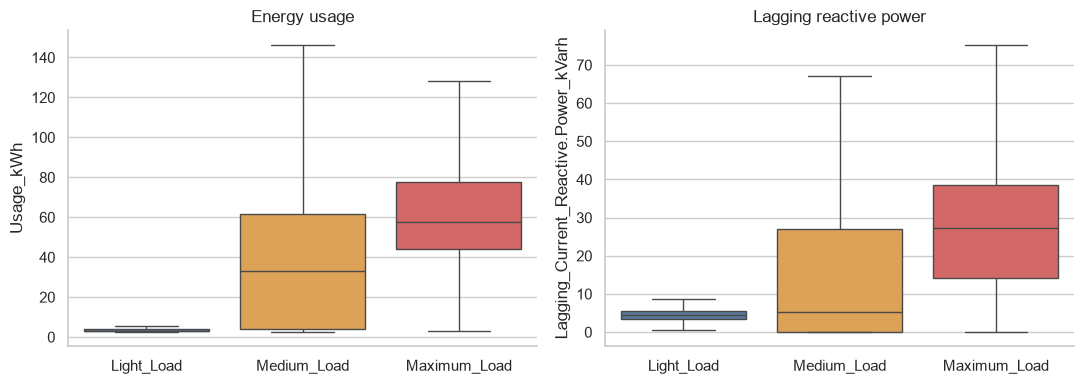

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=train, x='Load_Type', y='Usage_kWh', order=LABELS, hue='Load_Type', palette=COLORS,
            showfliers=False, ax=axes[0])
sns.boxplot(data=train, x='Load_Type', y='Lagging_Current_Reactive.Power_kVarh', order=LABELS, hue='Load_Type',
            palette=COLORS, showfliers=False, ax=axes[1])
axes[0].set(title='Energy usage', xlabel='')
axes[1].set(title='Lagging reactive power', xlabel='')
plt.tight_layout()
plt.show()

I see overlapping consumption ranges: some Maximum_Load readings use under 5 kWh, while some Light_Load
readings exceed 60 kWh. I interpret the labels as time-of-use categories, rather than consumption thresholds.


I find three daily label patterns: a March-October working day, a November-February working day, and an all-Light
day. All-Light days include Sundays, some Saturdays and weekdays consistent with holidays or shutdowns; the
calendar cannot identify every such day, which is why activity so far today helps. I count these on January-November below.


In [15]:
day_labels = train.assign(report_day=(train.index - pd.Timedelta('15min')).normalize()).pivot(
    index='report_day', columns='NSM', values='Load_Type')
assert day_labels.notna().all().all() and day_labels.shape[1] == 96
day_patterns = day_labels.apply(tuple, axis=1)
all_light_days = day_labels.eq('Light_Load').all(axis=1)
pattern_names = pd.Series(np.where(all_light_days, 'All-Light day',
    np.where(day_labels.index.month.isin([1, 2, 11, 12]), 'November-February working day',
             'March-October working day')), index=day_labels.index, name='pattern')
assert day_patterns.nunique() == 3
assert day_patterns.groupby(pattern_names).nunique().eq(1).all()
display(pattern_names.value_counts().rename('Jan-Nov days').to_frame())
off_day_types = pd.Series(np.where(day_labels.index.day_of_week == 6, 'Sunday',
    np.where(day_labels.index.day_of_week == 5, 'Saturday', 'Weekday')), index=day_labels.index)
display(off_day_types[all_light_days].value_counts().rename('All-Light days, Jan-Nov').to_frame())
extremes = pd.Series({
    'Maximum_Load below 5 kWh': ((train['Load_Type'] == 'Maximum_Load') & train[U].lt(5)).sum(),
    'Light_Load above 60 kWh': ((train['Load_Type'] == 'Light_Load') & train[U].gt(60)).sum(),
})
display(extremes.rename('Jan-Nov readings').to_frame())


,Jan-Nov days
pattern,
March-October working day,208
November-February working day,73
All-Light day,53


,"All-Light days, Jan-Nov"
Sunday,31
Weekday,11
Saturday,11


,Jan-Nov readings
Maximum_Load below 5 kWh,256
Light_Load above 60 kWh,622


## Features

I keep the calendar, six current readings, and previous-hour features as the reference. I then try:

- **Day activity:** mean and sum of usage since midnight and since 06:00, means over the previous 2 and 4 hours,
  maximum usage over the previous 2 hours, and the number of readings above 10 kWh in the previous hour.
- **Same slot:** usage and lagging reactive power yesterday and a week ago, plus their differences from now.

The 10 kWh threshold is a fixed activity indicator, not a fitted label boundary. I test the whole group in CV.
All summaries exclude the current reading; differences use the current measurement, which is already available.
Day summaries reset at midnight (and 06:00 for that group). Missing readings stay missing; rolling summaries
need at least half their window observed. I don't use previous labels or a holiday calendar: measured activity
is the candidate signal for working weekends and idle weekdays.


In [16]:
RAW = ['Usage_kWh', 'Lagging_Current_Reactive.Power_kVarh', 'Leading_Current_Reactive_Power_kVarh',
       'CO2(tCO2)', 'Lagging_Current_Power_Factor', 'Leading_Current_Power_Factor']
HISTORY = RAW[:3]
CALENDAR = ['hour', 'NSM', 'day_of_week', 'is_weekend', 'winter_schedule',
            'time_sin', 'time_cos', 'dow_sin', 'dow_cos']


def make_features(frame):
    X = frame[RAW].copy()
    t = frame.index
    X['hour'] = t.hour
    X['NSM'] = frame['NSM']
    X['day_of_week'] = t.day_of_week
    X['is_weekend'] = (t.day_of_week >= 5).astype(int)
    X['winter_schedule'] = t.month.isin([11, 12, 1, 2]).astype(int)
    X['time_sin'] = np.sin(2 * np.pi * X['NSM'] / 86400)
    X['time_cos'] = np.cos(2 * np.pi * X['NSM'] / 86400)
    X['dow_sin'] = np.sin(2 * np.pi * X['day_of_week'] / 7)
    X['dow_cos'] = np.cos(2 * np.pi * X['day_of_week'] / 7)
    for col in HISTORY:
        prev = frame[col].shift(1)
        X[f'{col}_lag1'] = prev
        X[f'{col}_lag4'] = frame[col].shift(4)
        X[f'{col}_prev_hour_mean'] = prev.rolling(4).mean()

    usage = frame['Usage_kWh']
    day = t.normalize()
    for name, values in [('midnight', usage), ('0600', usage.where(t.hour >= 6))]:
        # Shift within each date so the first row cannot borrow yesterday's activity.
        grouped = values.groupby(day)
        X[f'activity_{name}_mean'] = grouped.transform(lambda s: s.shift(1).expanding().mean())
        X[f'activity_{name}_sum'] = grouped.transform(lambda s: s.shift(1).expanding().sum())
    previous = usage.shift(1)
    X['activity_2h_mean'] = previous.rolling(8, min_periods=4).mean()
    X['activity_4h_mean'] = previous.rolling(16, min_periods=8).mean()
    X['activity_2h_max'] = previous.rolling(8, min_periods=4).max()
    active = usage.gt(10).where(usage.notna()).astype(float)
    X['activity_1h_count_above10'] = active.shift(1).rolling(4, min_periods=2).sum()
    for col in RAW[:2]:
        for name, periods in [('yesterday', 96), ('lastweek', 672)]:
            X[f'{name}_{col}'] = frame[col].shift(periods)
            X[f'{name}_{col}_difference'] = frame[col] - frame[col].shift(periods)
    return X


# Only Jan-Nov is built for selection. The same function is later applied to the full timeline.
features_train = make_features(train.drop(columns='Load_Type'))
BASE = RAW + CALENDAR + [c for c in features_train if c.endswith(('_lag1', '_lag4', '_prev_hour_mean'))]
ACTIVITY = [c for c in features_train if c.startswith('activity_')]
YESTERDAY = [c for c in features_train if c.startswith('yesterday_')]
LASTWEEK = [c for c in features_train if c.startswith('lastweek_')]
encoder = LabelEncoder().fit(LABELS)
y_train = encoder.transform(train['Load_Type'])

# A prefix must have identical features whether or not later measurements are present.
cut = 96 * 40 + 27
pd.testing.assert_frame_equal(features_train.iloc[:cut], make_features(train.iloc[:cut].drop(columns='Load_Type')))
assert pd.isna(features_train.loc['2018-01-02 00:00', 'activity_midnight_mean'])
print(f'{len(BASE)} reference features, {len(ACTIVITY)} activity features, {len(YESTERDAY + LASTWEEK)} same-slot features')


24 reference features, 8 activity features, 8 same-slot features


## Validation

I use the same five expanding `TimeSeriesSplit` folds on January-November for every comparison and randomized
search. All-fold macro F1 decides what I keep. I also report folds 2-5, since fold 1 has only seen January-February
and cannot learn the March-October schedule. The second number is context, not a different selection rule.

The validation rows can use earlier validation measurements as they arrive, but never their labels.
These are development CV scores reused for selection, so they can be optimistic; December remains the final check.


In [17]:
cv = TimeSeriesSplit(n_splits=5)
splits = list(cv.split(features_train))
for i, (tr, va) in enumerate(splits, 1):
    print(f'fold {i}: train to {train.index[tr[-1]]:%d %b}, validate {train.index[va[0]]:%d %b} - {train.index[va[-1]]:%d %b}')

# Tuned settings for the 24 reference features: calendar, current readings and previous hour.
REFERENCE_PARAMS = dict(subsample=0.8, reg_lambda=10, n_estimators=250, min_child_weight=1,
                  max_depth=7, learning_rate=0.06, colsample_bytree=0.8)


def xgb_model(**params):
    return xgb.XGBClassifier(random_state=SEED, n_jobs=THREADS, tree_method='hist', device='cpu', **params)


def lgb_model(**params):
    return lgb.LGBMClassifier(random_state=SEED, n_jobs=THREADS, verbosity=-1,
                              device_type='cpu', deterministic=True, force_col_wise=True, **params)


cv_rows = []


def record(name, scores, n_features):
    scores = np.asarray(scores)
    cv_rows.append({'idea': name, 'features': n_features, 'macro F1 (all)': scores.mean(),
                    'macro F1 (2-5)': scores[1:].mean(), 'fold 1': scores[0],
                    'per-fold macro F1': np.round(scores, 4).tolist()})


def evaluate(model, columns):
    return cross_validate(model, features_train[columns], y_train, cv=splits,
                          scoring='f1_macro', n_jobs=1)['test_score']


fold 1: train to 25 Feb, validate 25 Feb - 22 Apr
fold 2: train to 22 Apr, validate 22 Apr - 17 Jun
fold 3: train to 17 Jun, validate 17 Jun - 11 Aug
fold 4: train to 11 Aug, validate 11 Aug - 06 Oct
fold 5: train to 06 Oct, validate 06 Oct - 01 Dec


## Model and feature comparison

I compare the models on the 24 reference features: calendar, current readings and the previous hour.
I then hold `REFERENCE_PARAMS`, the tuned XGBoost settings for that reference set, fixed while testing each
extra feature group. This separates a feature change from a tuning change.

I also compare **range checks only** with **full cleaning**, using the same reference features and settings.
For range checks only, I set power factors outside 0-100 to NaN, recompute NSM and drop the duplicate.
I keep timestamps as written, without long-decimal detection, identity repair or the midnight fix.
Full cleaning uses all the repairs above. I use each version's timestamps for its features and split.
This shows what the full repair adds over a simple range check. The range-check row is a diagnostic and
cannot win selection. I report its December result in the post-hoc ablation.


In [18]:
from sklearn.base import BaseEstimator, ClassifierMixin


class HourOfWeekBaseline(ClassifierMixin, BaseEstimator):
    def fit(self, X, y):
        slot = X['day_of_week'] * 24 + X['hour']
        self.lookup_ = pd.Series(y, index=X.index).groupby(slot.values).agg(lambda s: s.mode()[0])
        self.default_ = pd.Series(y).mode()[0]
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        slot = X['day_of_week'] * 24 + X['hour']
        return slot.map(self.lookup_).fillna(self.default_).astype(int).to_numpy()



class SeasonalCalendarLookup(ClassifierMixin, BaseEstimator):
    columns = ['NSM', 'day_of_week', 'winter_schedule']

    def fit(self, X, y):
        frame = X[self.columns].assign(label=np.asarray(y))
        self.lookup_ = frame.groupby(self.columns)['label'].agg(lambda s: s.mode().iloc[0])
        self.default_ = pd.Series(y).mode().iloc[0]
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        keys = pd.MultiIndex.from_frame(X[self.columns])
        return self.lookup_.reindex(keys).fillna(self.default_).to_numpy(dtype=int)


models = {
    'Hour-of-week baseline': HourOfWeekBaseline(),
    'Seasonal calendar lookup': SeasonalCalendarLookup(),
    'Logistic regression': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                         LogisticRegression(max_iter=2000)),
    'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=THREADS, random_state=SEED),
    'LightGBM': lgb_model(n_estimators=300, learning_rate=0.05),
    'XGBoost': xgb_model(n_estimators=300, learning_rate=0.05, max_depth=5),
}


for name, model in models.items():
    columns = SeasonalCalendarLookup.columns if isinstance(model, SeasonalCalendarLookup) else BASE
    record(name + ' / reference', evaluate(model, columns), len(columns))
    print(f'{name}: {cv_rows[-1]["macro F1 (all)"]:.4f}', flush=True)

# Range checks only: keep written timestamps, with no decimal detection or identity repair.
range_only_df = raw.drop_duplicates('Date_Time', keep='first').set_index('Date_Time').sort_index()
for col in RAW[4:]:
    range_only_df.loc[~range_only_df[col].between(0, 100), col] = np.nan
range_only_df['NSM'] = range_only_df.index.hour * 3600 + range_only_df.index.minute * 60
range_only_train = range_only_df.loc[range_only_df.index < '2018-12-01']
range_only_X = make_features(range_only_train.drop(columns='Load_Type'))[BASE]
range_only_y = encoder.transform(range_only_train['Load_Type'])
range_only_scores = cross_validate(xgb_model(**REFERENCE_PARAMS), range_only_X, range_only_y, cv=splits,
                            scoring='f1_macro', n_jobs=1)['test_score']
record('Range checks only / reference XGBoost', range_only_scores, len(BASE))

feature_sets = {
    'Reference XGBoost': BASE,
    '+ day activity': BASE + ACTIVITY,
    '+ same slot yesterday': BASE + YESTERDAY,
    '+ same slot last week': BASE + LASTWEEK,
    '+ yesterday and last week': BASE + YESTERDAY + LASTWEEK,
    '+ activity and both slots': BASE + ACTIVITY + YESTERDAY + LASTWEEK,
}
feature_scores = {}
for name, columns in feature_sets.items():
    scores = evaluate(xgb_model(**REFERENCE_PARAMS), columns)
    feature_scores[name] = scores
    record(name, scores, len(columns))
    print(f'{name}: {scores.mean():.4f}', flush=True)

# Tune on the best expanded set; the reference set is still eligible to win overall.
expanded = [name for name in feature_sets if name != 'Reference XGBoost']
best_features_name = max(expanded, key=lambda name: feature_scores[name].mean())
selected_columns = feature_sets[best_features_name]
display(pd.DataFrame(cv_rows).set_index('idea').round(4))
print('Expanded features for tuning:', best_features_name)

# This diagnostic has no measurements, and is fitted before opening December.
calendar_lookup = SeasonalCalendarLookup().fit(features_train[SeasonalCalendarLookup.columns], y_train)


Hour-of-week baseline: 0.7455


Seasonal calendar lookup: 0.8064


Logistic regression: 0.7773


Random forest: 0.8878


LightGBM: 0.8938


...

+ same slot last week: 0.8940


+ yesterday and last week: 0.8967


+ activity and both slots: 0.9215


,features,macro F1 (all),macro F1 (2-5),fold 1,per-fold macro F1
idea,,,,,
Hour-of-week baseline / reference,24,0.7455,0.7854,0.5860,"[0.586, 0.7179, 0.8441, 0.8564, 0.723]"
Seasonal calendar lookup / reference,3,0.8064,0.9342,0.2952,"[0.2952, 0.9368, 0.9161, 0.9153, 0.9687]"
Logistic regression / reference,24,0.7773,0.8278,0.5754,"[0.5754, 0.8485, 0.8772, 0.8631, 0.7225]"
Random forest / reference,24,0.8878,0.9578,0.6076,"[0.6076, 0.9657, 0.9636, 0.9456, 0.9564]"
LightGBM / reference,24,0.8938,0.9653,0.6076,"[0.6076, 0.9766, 0.9669, 0.9565, 0.9613]"
XGBoost / reference,24,0.8939,0.9655,0.6076,"[0.6076, 0.9773, 0.9662, 0.9571, 0.9614]"
Range checks only / reference XGBoost,24,0.8930,0.9649,0.6056,"[0.6056, 0.9744, 0.9661, 0.9572, 0.9618]"
Reference XGBoost,24,0.8934,0.9649,0.6074,"[0.6074, 0.9762, 0.966, 0.9576, 0.9595]"
+ day activity,32,0.9213,0.9931,0.6342,"[0.6342, 0.9966, 1.0, 0.9892, 0.9866]"


Expanded features for tuning: + activity and both slots


## Tuning and class weights

I try eight random settings for each model, both without weights and with inverse-frequency class weights.
The same eight settings are used for each weighting option. Weights are learned separately inside each training
fold. Each search uses macro F1 and the same five time splits. Four CPU threads per fit keep the search small.

Finally, I average XGBoost and LightGBM probabilities 50:50, once for the unweighted pair and once for the
weighted pair. I don't tune a voting weight or prediction threshold. All choices below use January-November only.


In [19]:
class FoldWeights(ClassifierMixin, BaseEstimator):
    def __init__(self, estimator, balanced=False):
        self.estimator = estimator
        self.balanced = balanced

    def fit(self, X, y):
        weights = compute_sample_weight('balanced', y) if self.balanced else None
        self.estimator_ = clone(self.estimator).fit(X, y, sample_weight=weights)
        self.classes_ = self.estimator_.classes_
        return self

    def predict(self, X):
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)


spaces = {
    'XGBoost': {
        'estimator__n_estimators': [150, 250, 350],
        'estimator__learning_rate': [0.04, 0.06, 0.1],
        'estimator__max_depth': [3, 5, 7],
        'estimator__min_child_weight': [1, 5, 12],
        'estimator__subsample': [0.8, 1.0],
        'estimator__colsample_bytree': [0.8, 1.0],
        'estimator__reg_lambda': [1, 5, 10],
    },
    'LightGBM': {
        'estimator__n_estimators': [150, 250, 350],
        'estimator__learning_rate': [0.04, 0.06, 0.1],
        'estimator__num_leaves': [15, 31, 63],
        'estimator__max_depth': [-1, 5, 7],
        'estimator__min_child_samples': [15, 40, 80],
        'estimator__colsample_bytree': [0.8, 1.0],
        'estimator__reg_lambda': [0, 5, 10],
    },
}
searches, tuned, oof = {}, {}, {}
for family, base in [('XGBoost', xgb_model()), ('LightGBM', lgb_model())]:
    for balanced in [False, True]:
        name = family + (' / balanced' if balanced else ' / unweighted')
        search = RandomizedSearchCV(FoldWeights(base, balanced), spaces[family], n_iter=8,
                                    scoring='f1_macro', cv=splits, random_state=SEED,
                                    n_jobs=1, refit=False, error_score='raise')
        search.fit(features_train[selected_columns], y_train)
        searches[name] = search
        params = {key.removeprefix('estimator__'): value for key, value in search.best_params_.items()}
        tuned[name] = (clone(base).set_params(**params), balanced)
        scores = [search.cv_results_[f'split{i}_test_score'][search.best_index_] for i in range(5)]
        record(name, scores, len(selected_columns))
        # Fold predictions are also needed for the probability average.
        probabilities = np.full((len(train), len(encoder.classes_)), np.nan)
        for tr, va in splits:
            model = FoldWeights(tuned[name][0], balanced).fit(features_train.iloc[tr][selected_columns], y_train[tr])
            probabilities[va] = model.predict_proba(features_train.iloc[va][selected_columns])
        oof[name] = probabilities
        print(f'{name}: {np.mean(scores):.4f}; {params}')

ensemble_scores = {}
for balanced in [False, True]:
    suffix = ' / balanced' if balanced else ' / unweighted'
    probabilities = (oof['XGBoost' + suffix] + oof['LightGBM' + suffix]) / 2
    scores = [f1_score(y_train[va], probabilities[va].argmax(axis=1), average='macro') for _, va in splits]
    name = 'Soft vote' + suffix
    ensemble_scores[name] = scores
    record(name, scores, len(selected_columns))

cv_table = pd.DataFrame(cv_rows).set_index('idea')
display(cv_table.round(4))

# The range-check diagnostic is ineligible; idxmax resolves ties in table order.
eligible = [name for name in cv_table.index if name != 'Range checks only / reference XGBoost']
winner = cv_table.loc[eligible, 'macro F1 (all)'].idxmax()
if winner.endswith(' / reference'):
    final_columns = BASE
    final_template, final_balanced = models[winner.removesuffix(' / reference')], False
elif winner in feature_sets:
    final_columns = feature_sets[winner]
    final_template, final_balanced = xgb_model(**REFERENCE_PARAMS), False
elif winner in tuned:
    final_columns = selected_columns
    final_template, final_balanced = tuned[winner]
else:
    final_columns = selected_columns
    suffix = winner.removeprefix('Soft vote')
    final_balanced = suffix == ' / balanced'
    final_template = VotingClassifier(
        estimators=[('xgb', tuned['XGBoost' + suffix][0]), ('lgb', tuned['LightGBM' + suffix][0])],
        voting='soft', n_jobs=1)
print(f'Locked before December: {winner}; {len(final_columns)} features; CV macro F1 {cv_table.loc[winner, "macro F1 (all)"]:.4f}')


XGBoost / unweighted: 0.9242; {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 350, 'min_child_weight': 12, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


XGBoost / balanced: 0.9245; {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 350, 'min_child_weight': 12, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


LightGBM / unweighted: 0.9239; {'reg_lambda': 0, 'num_leaves': 63, 'n_estimators': 250, 'min_child_samples': 40, 'max_depth': 5, 'learning_rate': 0.06, 'colsample_bytree': 1.0}


LightGBM / balanced: 0.9241; {'reg_lambda': 10, 'num_leaves': 31, 'n_estimators': 350, 'min_child_samples': 80, 'max_depth': 5, 'learning_rate': 0.06, 'colsample_bytree': 1.0}


,features,macro F1 (all),macro F1 (2-5),fold 1,per-fold macro F1
idea,,,,,
Hour-of-week baseline / reference,24,0.7455,0.7854,0.5860,"[0.586, 0.7179, 0.8441, 0.8564, 0.723]"
Seasonal calendar lookup / reference,3,0.8064,0.9342,0.2952,"[0.2952, 0.9368, 0.9161, 0.9153, 0.9687]"
Logistic regression / reference,24,0.7773,0.8278,0.5754,"[0.5754, 0.8485, 0.8772, 0.8631, 0.7225]"
Random forest / reference,24,0.8878,0.9578,0.6076,"[0.6076, 0.9657, 0.9636, 0.9456, 0.9564]"
LightGBM / reference,24,0.8938,0.9653,0.6076,"[0.6076, 0.9766, 0.9669, 0.9565, 0.9613]"
XGBoost / reference,24,0.8939,0.9655,0.6076,"[0.6076, 0.9773, 0.9662, 0.9571, 0.9614]"
Range checks only / reference XGBoost,24,0.8930,0.9649,0.6056,"[0.6056, 0.9744, 0.9661, 0.9572, 0.9618]"
Reference XGBoost,24,0.8934,0.9649,0.6074,"[0.6074, 0.9762, 0.966, 0.9576, 0.9595]"
+ day activity,32,0.9213,0.9931,0.6342,"[0.6342, 0.9966, 1.0, 0.9892, 0.9866]"


Locked before December: XGBoost / balanced; 40 features; CV macro F1 0.9245


Class-weighted XGBoost with all 40 features has the best all-fold macro F1, so that's the model I keep.
LightGBM and the 50:50 averages are within 0.001 but don't beat it.

## Final evaluation on December

The model, features and class weights are now fixed by CV. I refit on all of January-November and predict
December once. Every metric, confidence interval and error table below uses those same predictions.

As a reference point I also score a calendar-only lookup (most common label for each time of day, weekday and
season). It doesn't affect the model choice.

In [20]:
features = make_features(df.drop(columns='Load_Type'))
pd.testing.assert_frame_equal(features.loc[train.index], features_train)
X_train = features.loc[train.index, final_columns]
X_test = features.loc[test.index, final_columns]
y_test = encoder.transform(test['Load_Type'])
weights = compute_sample_weight('balanced', y_train) if final_balanced else None
final_model = clone(final_template).fit(X_train, y_train, sample_weight=weights)
proba = final_model.predict_proba(X_test)
assert np.array_equal(final_model.classes_, np.arange(len(encoder.classes_)))
pred = proba.argmax(axis=1)
precision, recall, macro_f1, _ = precision_recall_fscore_support(y_test, pred, average='macro')
metrics = pd.Series({
    'accuracy': accuracy_score(y_test, pred),
    'macro precision': precision,
    'macro recall / balanced accuracy': balanced_accuracy_score(y_test, pred),
    'macro F1': macro_f1,
    'weighted F1': f1_score(y_test, pred, average='weighted'),
    "Cohen's kappa": cohen_kappa_score(y_test, pred),
    'MCC': matthews_corrcoef(y_test, pred),
    'macro OVR ROC-AUC': roc_auc_score(y_test, proba, labels=final_model.classes_, multi_class='ovr', average='macro'),
    'log loss': log_loss(y_test, proba, labels=final_model.classes_),
}, name='December')
display(metrics.to_frame().round(5))
print(classification_report(y_test, pred, labels=encoder.transform(LABELS), target_names=LABELS, digits=4))


,December
accuracy,0.99832
macro precision,0.99776
macro recall / balanced accuracy,0.99876
macro F1,0.99826
weighted F1,0.99832
Cohen's kappa,0.99705
MCC,0.99705
macro OVR ROC-AUC,1.00000
log loss,0.00662


              precision    recall  f1-score   support

  Light_Load     0.9994    0.9977    0.9986      1744
 Medium_Load     0.9958    0.9986    0.9972       704
Maximum_Load     0.9981    1.0000    0.9991       528

    accuracy                         0.9983      2976
   macro avg     0.9978    0.9988    0.9983      2976
weighted avg     0.9983    0.9983    0.9983      2976



I resample complete dates, with replacement, 1,000 times (seed 42). Adding their confusion matrices gives exactly
the same accuracy and macro F1 as concatenating those days, while preserving dependence within each day.
The percentile intervals describe variation across December days; they do not include training or model-selection
uncertainty, and treating dates as independent can miss dependence across consecutive days.


In [21]:
dates = (test.index - pd.Timedelta('15min')).normalize()
day_matrices = np.stack([confusion_matrix(y_test[dates == date], pred[dates == date], labels=np.arange(3))
                         for date in dates.unique()])
assert np.array_equal(day_matrices.sum(axis=0), confusion_matrix(y_test, pred, labels=np.arange(3)))
assert len(day_matrices) == 31 and np.all(day_matrices.sum(axis=(1, 2)) == 96)
rng = np.random.default_rng(SEED)
draws = rng.integers(0, len(day_matrices), size=(1000, len(day_matrices)))
boot_matrices = day_matrices[draws].sum(axis=1)
tp = np.diagonal(boot_matrices, axis1=1, axis2=2)
boot_accuracy = tp.sum(axis=1) / boot_matrices.sum(axis=(1, 2))
denom = boot_matrices.sum(axis=1) + boot_matrices.sum(axis=2)
boot_f1 = np.divide(2 * tp, denom, out=np.zeros_like(tp, dtype=float), where=denom != 0).mean(axis=1)
intervals = pd.DataFrame({'estimate': [metrics['accuracy'], macro_f1],
                          '95% lower': [np.quantile(boot_accuracy, .025), np.quantile(boot_f1, .025)],
                          '95% upper': [np.quantile(boot_accuracy, .975), np.quantile(boot_f1, .975)]},
                         index=['accuracy', 'macro F1'])
display(intervals.round(5))


,estimate,95% lower,95% upper
accuracy,0.99832,0.99530,1.0
macro F1,0.99826,0.99505,1.0


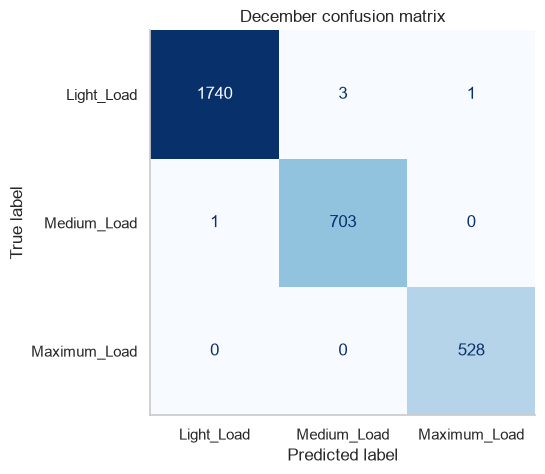

In [22]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(encoder.inverse_transform(y_test), encoder.inverse_transform(pred),
                                        labels=LABELS, cmap='Blues', colorbar=False, ax=ax)
ax.set_title('December confusion matrix')
ax.grid(False)
plt.show()


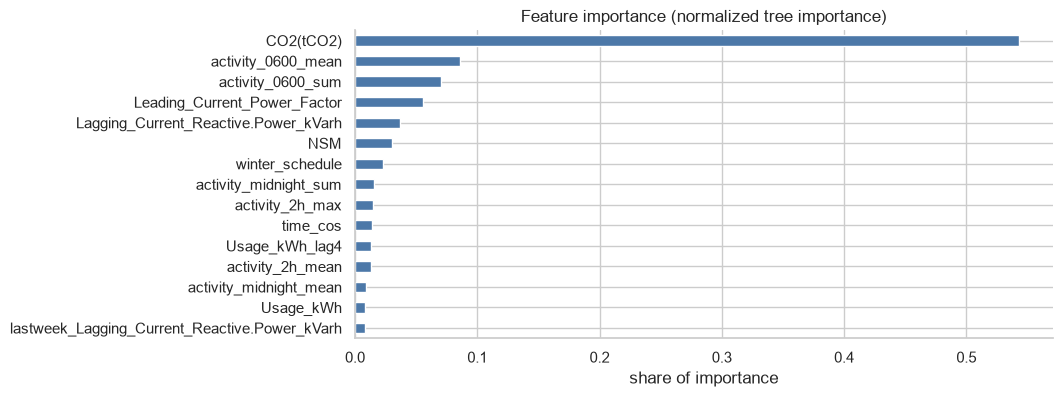

In [23]:
# For a vote, average each member's normalized importance so both have equal influence.
members = final_model.estimators_ if isinstance(final_model, VotingClassifier) else [final_model]
importance = np.mean([m.feature_importances_ / m.feature_importances_.sum() for m in members], axis=0)
importance = pd.Series(importance, index=final_columns).nlargest(15)
ax = importance.sort_values().plot.barh(color=COLORS[0], title='Feature importance (normalized tree importance)')
ax.set_xlabel('share of importance')
plt.show()


## Where the December errors fall

I count errors and their rates for weekdays/weekends and four fixed hour bands. These tables describe the held-out
result; I don't use them to revise the model.


In [24]:
errors = pd.DataFrame({'error': pred != y_test,
                        'day type': np.where(dates.day_of_week >= 5, 'Weekend', 'Weekday'),
                        'hour band': pd.cut(test.index.hour, bins=[-1, 8, 12, 17, 23],
                                            labels=['00:00-08:59', '09:00-12:59', '13:00-17:59', '18:00-23:59'])},
                       index=test.index)


def error_summary(group):
    result = errors.groupby(group, observed=True)['error'].agg(readings='size', errors='sum', error_rate='mean')
    result['accuracy'] = 1 - result['error_rate']
    return result


by_day_type = error_summary('day type')
by_hour_band = error_summary('hour band')
display(by_day_type.round(4))
display(by_hour_band.round(4))
print(f'Total errors: {errors.error.sum()} / {len(errors)}')


,readings,errors,error_rate,accuracy
day type,,,,
Weekday,2016,0,0.0000,1.0000
Weekend,960,5,0.0052,0.9948


,readings,errors,error_rate,accuracy
hour band,,,,
00:00-08:59,1116,0,0.0000,1.0000
09:00-12:59,496,4,0.0081,0.9919
13:00-17:59,620,1,0.0016,0.9984
18:00-23:59,744,0,0.0000,1.0000


Total errors: 5 / 2976


## Post-hoc ablation: cleaning and features

I use these comparisons to explain the result after selection; I don't use them to choose a model.
The cleaning table holds the 24 reference features and `REFERENCE_PARAMS` fixed. It shows what full cleaning
adds over range checks only, in CV and December.

For the feature table, I use full cleaning throughout. I fit calendar only (9 features), add current readings
(15), then add the previous hour (24), all with `REFERENCE_PARAMS`. The last row uses the chosen model's
40 features and final settings, including class weights. I reuse its CV scores and December predictions.


In [25]:
range_only_test = range_only_df.loc[range_only_df.index >= '2018-12-01']
range_only_test_X = make_features(range_only_df.drop(columns='Load_Type')).loc[range_only_test.index, BASE]
range_only_model = xgb_model(**REFERENCE_PARAMS).fit(range_only_X, range_only_y)
range_only_pred = range_only_model.predict(range_only_test_X)
range_only_test_y = encoder.transform(range_only_test['Load_Type'])
range_only_accuracy = accuracy_score(range_only_test_y, range_only_pred)
range_only_f1 = f1_score(range_only_test_y, range_only_pred, average='macro')

ablation_rows = []
for name, columns in [('Calendar only', CALENDAR), ('+ current readings', RAW + CALENDAR),
                      ('+ previous hour (reference)', BASE)]:
    model = xgb_model(**REFERENCE_PARAMS).fit(features.loc[train.index, columns], y_train)
    ablation_pred = model.predict(features.loc[test.index, columns])
    scores = feature_scores['Reference XGBoost'] if columns == BASE else evaluate(xgb_model(**REFERENCE_PARAMS), columns)
    ablation_rows.append((name, len(columns), scores.mean(), scores[1:].mean(),
                          accuracy_score(y_test, ablation_pred), f1_score(y_test, ablation_pred, average='macro')))
    if columns == BASE:
        reference_accuracy = accuracy_score(y_test, ablation_pred)
        reference_f1 = f1_score(y_test, ablation_pred, average='macro')

ablation_rows.append(('Final model', len(final_columns), cv_table.loc[winner, 'macro F1 (all)'],
                      cv_table.loc[winner, 'macro F1 (2-5)'], metrics['accuracy'], macro_f1))
ablation = pd.DataFrame(ablation_rows, columns=['features (full cleaning)', 'n', 'CV macro F1 (all)',
                                              'CV macro F1 (2-5)', 'December accuracy',
                                              'December macro F1']).set_index('features (full cleaning)')
reference_scores = feature_scores['Reference XGBoost']
cleaning_ablation = pd.DataFrame([
    ('Range checks only', range_only_scores.mean(), range_only_scores[1:].mean(),
     range_only_accuracy, range_only_f1),
    ('Full cleaning', reference_scores.mean(), reference_scores[1:].mean(), reference_accuracy, reference_f1),
], columns=['cleaning (24 reference features)', 'CV macro F1 (all)', 'CV macro F1 (2-5)',
            'December accuracy', 'December macro F1']).set_index('cleaning (24 reference features)')
display(cleaning_ablation.round(5))
display(ablation.round(5))


# The seasonal calendar diagnostic is fixed on Jan-Nov, with no December tuning.
calendar_lookup_pred = calendar_lookup.predict(features.loc[test.index, SeasonalCalendarLookup.columns])
calendar_lookup_accuracy = accuracy_score(y_test, calendar_lookup_pred)
calendar_lookup_f1 = f1_score(y_test, calendar_lookup_pred, average='macro')
print(f'Seasonal calendar lookup: December accuracy {calendar_lookup_accuracy:.5f}, macro F1 {calendar_lookup_f1:.5f}')
full_year_light = df['Load_Type'].eq('Light_Load').groupby(reporting_date).all()
print(f'All-Light days: Jan-Nov {all_light_days.sum()} / {len(all_light_days)}, full year {full_year_light.sum()} / {len(full_year_light)}')


,CV macro F1 (all),CV macro F1 (2-5),December accuracy,December macro F1
cleaning (24 reference features),,,,
Range checks only,0.89303,0.96487,0.95934,0.95559
Full cleaning,0.89336,0.96486,0.95934,0.95546


,n,CV macro F1 (all),CV macro F1 (2-5),December accuracy,December macro F1
features (full cleaning),,,,,
Calendar only,9,0.86924,0.93424,0.88710,0.88235
+ current readings,15,0.88229,0.95533,0.95665,0.95119
+ previous hour (reference),24,0.89336,0.96486,0.95934,0.95546
Final model,40,0.92451,0.99708,0.99832,0.99826


Seasonal calendar lookup: December accuracy 0.88710, macro F1 0.88235
All-Light days: Jan-Nov 53 / 334, full year 62 / 365


In [26]:
Path('models').mkdir(exist_ok=True)
Path('outputs').mkdir(exist_ok=True)
joblib.dump({'model': final_model, 'encoder': encoder, 'features': list(final_columns)},
            'models/load_type_model.joblib')
pd.DataFrame({'Date_Time': test.index, 'actual': test['Load_Type'],
              'predicted': encoder.inverse_transform(pred)}).to_csv('outputs/december_predictions.csv', index=False)
elapsed = time.perf_counter() - started
print(f'Notebook run time: {elapsed:.1f} seconds ({elapsed / 60:.2f} minutes), CPU only')


Notebook run time: 275.5 seconds (4.59 minutes), CPU only


## Conclusions

- **Final model:** class-weighted XGBoost with 40 features, chosen on January-November CV only.
  CV macro F1 is **0.9245** over all folds and **0.9971** over folds 2-5.
- **December:** accuracy **0.99832** (day-bootstrap 95% CI 0.99530-1.00000), macro F1 **0.99826**
  (95% CI 0.99505-1.00000), macro precision 0.99776, balanced accuracy / macro recall 0.99876.
  The 24 reference features reach **0.95934** accuracy and **0.95546** macro F1 on December.
  With activity and same-slot features at the final settings, I reach the December scores above.
- **Errors:** 5 of 2,976 readings, all on weekends.
- **What the label means:** the labels follow a time-of-use schedule with three day patterns: a March-October
  working day, a November-February working day, and an all-Light day (53 in January-November, 62 in the year).
  The calendar can't tell which days the plant is off, so a calendar-only lookup reaches only **0.887** on
  December. How busy the plant has been so far today fills that gap, and it's where almost all the improvement
  comes from. Some Maximum_Load readings use under 5 kWh and some Light_Load readings exceed 60 kWh, so the label
  is a tariff period, not a consumption level.
- **Cleaning:** about 10% of non-zero values in every measurement column were injected (the true value multiplied
  by roughly 1.5-3, stored with long decimals). I set them to missing and rebuild them, and the blanks, from the
  power-factor and CO2 identities in the same row. I also fix 41 zero CO2 values on 2 January, leave the power
  factors undefined on 1 all-zero row, correct 365 midnight dates (12 of which cross into the next month), and keep
  the first copy of the duplicated reading. Labels are unchanged; I found no label noise.
- **Cleaning on its own:** with the 24 reference features and `REFERENCE_PARAMS`, range checks only /
  full cleaning gives CV macro F1 0.89303 / 0.89336 across all folds and 0.96487 / 0.96486 over folds 2-5.
  December accuracy is 0.95934 / 0.95934 and macro F1 is 0.95559 / 0.95546. The repair makes the data
  correct; the score gain comes from the activity features.
- **Boundary:** timestamps mark the end of each 15-minute interval. December is 2018-12-01 00:15 to
  2019-01-01 00:00, 2,976 readings.
- **Limits:** this classifies a reading once it arrives; it isn't a forecast. One year means each season is seen
  once, fold 1 hasn't seen the summer schedule, and CV was reused for selection, so CV scores may be slightly
  optimistic. The bootstrap intervals cover day-to-day variation in December, not training uncertainty. No future
  readings, previous labels, time interpolation or holiday calendar are used.
- **Run time:** about 5 minutes on a laptop CPU.